In [ ]:
import cv2
import numpy as np

# Data warna sesuai Tabel 7 dalam urutan RGB
bercak = np.uint8([[[196, 178, 86]]])
daun = np.uint8([[[52, 136, 60]]])

# Konversi RGB ke HSV
hsv_bercak = cv2.cvtColor(bercak, cv2.COLOR_RGB2HSV)
hsv_daun = cv2.cvtColor(daun, cv2.COLOR_RGB2HSV)

# Mengambil nilai Hue (kanal pertama)
hue_bercak = hsv_bercak[0, 0, 0]
hue_daun = hsv_daun[0, 0, 0]

print("Hue bercak:", hue_bercak)
print("Hue daun sehat:", hue_daun)

Hue bercak: 25
Hue daun sehat: 63


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Langkah 2.3 Kanal warna

Kode 2.1 Pemisahan kanal dan Kontras Bercak

KB kanal B   : 2.03
KB kanal G   : 0.46
KB kanal R   : 11.49
KB kanal Gray: 4.55
KB kanal H   : 9.39
KB kanal S   : 1.03
KB kanal V   : 2.49


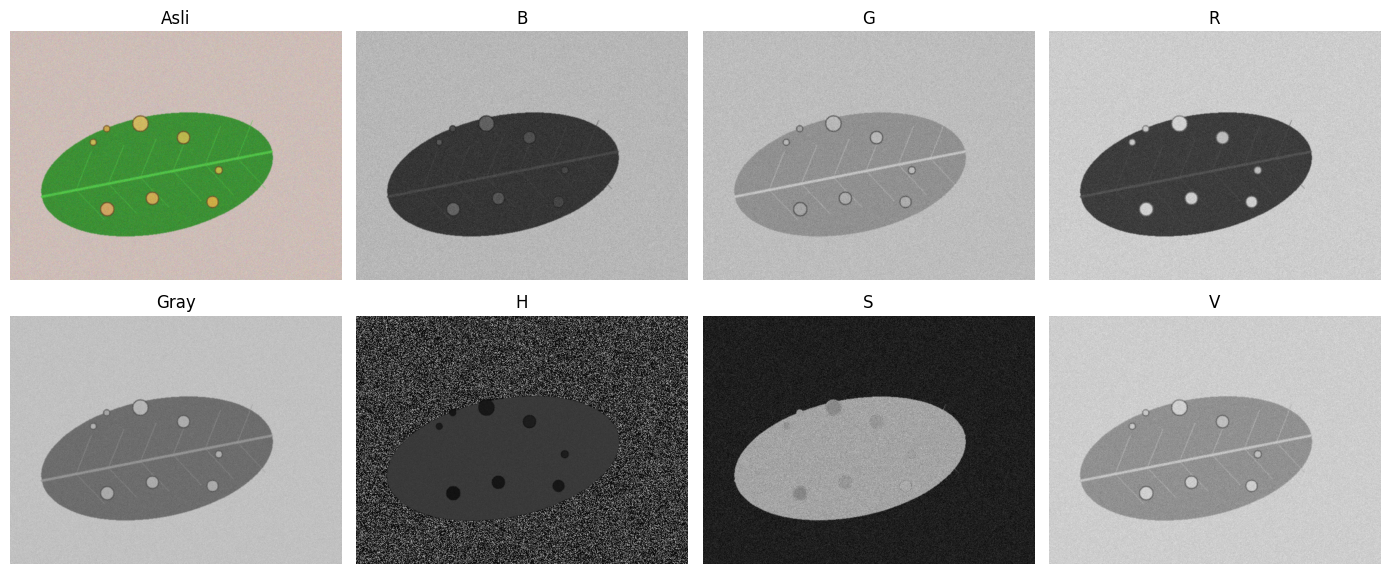

In [ ]:
from utils_cv import kontras_bercak

nama = "teh_041.png"  # kelas berat, kondisi normal

img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {
    "B": b,
    "G": g,
    "R": r,
    "Gray": gray,
    "H": h,
    "S": s,
    "V": v
}

tampil(
    [img] + list(kanal.values()),
    ["Asli"] + list(kanal.keys()),
    baris=2,
    ukuran=(14, 6)
)

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

**Langkah 2.4 Eksperimen sampling dan kuantisasi.**
Kode 2.2 Samplin dan kuantisasi

In [ ]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
 kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
 besar = cv2.resize(kecil, gray.shape[::-1],
 interpolation=cv2.INTER_NEAREST)
 print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md,
mb):.2f}")
# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
 langkah = 256 // (2 ** k)
 kuant = (gray // langkah) * langkah
 print(f"k={k}: {len(np.unique(kuant))} level, "
 f"KB={kontras_bercak(kuant, md, mb):.2f}")


fx=0.5: ukuran (240, 320), KB=5.23
fx=0.2: ukuran (96, 128), KB=4.74
fx=0.1: ukuran (48, 64), KB=3.25
fx=0.05: ukuran (24, 32), KB=1.78
k=1: 2 level, KB=3.35
k=2: 3 level, KB=3.37
k=3: 5 level, KB=5.33
k=4: 10 level, KB=3.85
k=8: 141 level, KB=4.55


**Langkah 2.5 Uji di seluruh kondisi cahaya**

Kode 2.3 Rerata KB per kanal dan per kondisi

In [ ]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }


# Membaca data label
label = pd.read_csv("../data/sintetis/label.csv")

baris = []

# Menghitung kontras bercak untuk setiap citra kelas berat
for _, d in label[label.kelas == "berat"].iterrows():

    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)


# Mengelompokkan hasil berdasarkan kondisi cahaya
tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print(tabel_kb)

# Menyimpan hasil ke file CSV
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        0.59  0.37  5.14  1.28  4.91  0.53  0.72
gelap           1.29  0.75  9.04  3.72  5.33  1.14  2.52
kontras_rendah  0.95  0.83  4.19  2.61  1.97  0.26  1.94
normal          1.22  0.96  9.76  4.51  7.44  0.68  2.66
terang          3.23  0.73  7.86  4.33  6.42  1.82  2.10


**Langkah 2.6 Kerjakan sendiri**

Menghitung rerata KB dari 20 citra kelas ringan (teh_021 sampai teh_040)

In [ ]:
# Membaca data label
label = pd.read_csv("../data/sintetis/label.csv")

baris_ringan = []

# Menghitung KB untuk 20 citra kelas ringan
for _, d in label[label.kelas == "ringan"].iterrows():

    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)


# Mengelompokkan hasil berdasarkan kondisi cahaya
tabel_kb_ringan = (
    pd.DataFrame(baris_ringan)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print(tabel_kb_ringan)

# Memeriksa jumlah citra dan kondisi cahaya
print("Jumlah citra yang diproses:", len(baris_ringan))
print("Jumlah kondisi cahaya:", len(tabel_kb_ringan))

# Menyimpan hasil
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.01  0.53  4.42  1.42  3.77  0.53  1.02
gelap           1.06  0.94  8.62  3.58  5.03  0.71  2.89
kontras_rendah  0.54  0.22  3.71  1.67  2.12  0.30  0.95
normal          2.05  0.71  8.18  3.65  6.72  1.23  1.96
terang          1.19  0.26  5.57  2.42  4.67  0.50  1.36
Jumlah citra yang diproses: 20
Jumlah kondisi cahaya: 5


**Langkah 2.6 Kerjakan sendiri**
Menampilkan kanal terbaik untuk ke dua citra
*   teh_021.png - kelas ringan, kondisi normal
*   teh_045.png - kelas berat, kondisi bayangan




Citra: teh_021.png (Ringan - Normal)
Nilai KB setiap kanal:
B: 1.80
G: 0.80
R: 8.69
Gray: 3.98
H: 7.14
S: 0.57
V: 2.47
Kanal terbaik: R

Citra: teh_045.png (Berat - Bayangan)
Nilai KB setiap kanal:
B: 0.35
G: 0.10
R: 3.74
Gray: 1.01
H: 4.16
S: 0.04
V: 0.65
Kanal terbaik: H


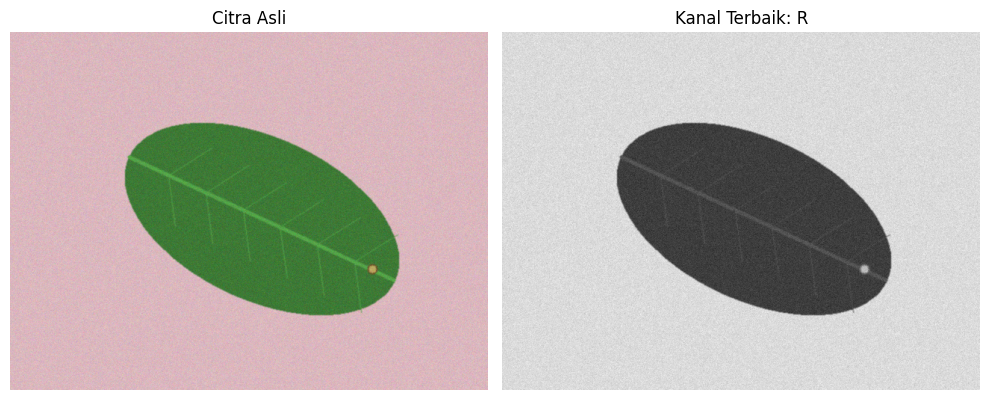

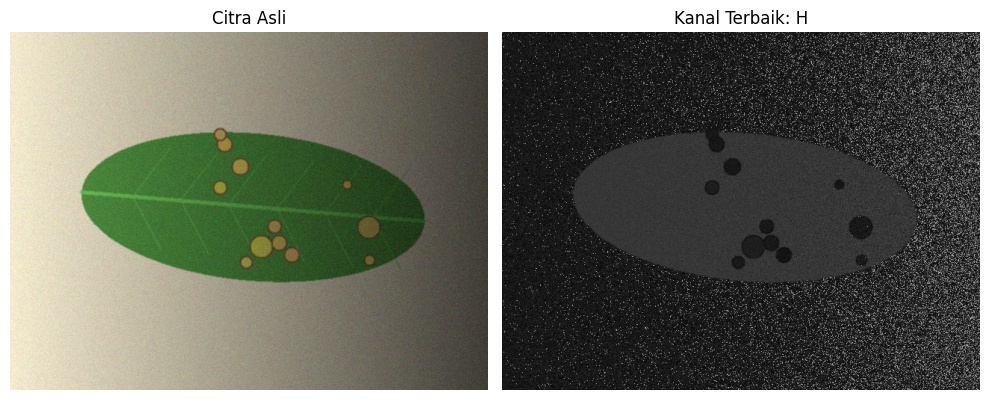

In [ ]:
# Citra yang akan diamati
daftar_citra = [
    ("teh_021.png", "Ringan - Normal"),
    ("teh_045.png", "Berat - Bayangan")
]

for nama, keterangan in daftar_citra:

    # Membaca citra
    img = baca(f"../data/sintetis/citra/{nama}")

    # Mengambil seluruh kanal warna
    kanal = semua_kanal(img)

    # Menampilkan nilai KB setiap kanal
    md = cv2.imread(
        f"../data/sintetis/mask_daun/{nama}", 0
    )
    mb = cv2.imread(
        f"../data/sintetis/mask_bercak/{nama}", 0
    )

    nilai_kb = {
        k: kontras_bercak(c, md, mb)
        for k, c in kanal.items()
    }

    # Menentukan kanal dengan nilai KB tertinggi
    kanal_terbaik = max(nilai_kb, key=nilai_kb.get)

    print(f"\nCitra: {nama} ({keterangan})")
    print("Nilai KB setiap kanal:")
    for k, nilai in nilai_kb.items():
        print(f"{k}: {nilai:.2f}")

    print("Kanal terbaik:", kanal_terbaik)

    # Menampilkan citra asli dan kanal terbaik
    tampil(
        [img, kanal[kanal_terbaik]],
        ["Citra Asli", f"Kanal Terbaik: {kanal_terbaik}"],
        baris=1,
        ukuran=(10, 4)
    )